In [25]:
import numpy as np
import matplotlib.pyplot as plt
from nnfs.datasets import spiral_data
from sklearn.preprocessing import OneHotEncoder

### Individual Layers in NN

In [2]:
# 4 i/p, 2 hidden layers with 3 Neurons
x = np.random.rand(3, 4) # 3 batch of i/p
w0 = np.random.rand(3, 4) # assinging weights to each i/p
w1 = np.random.rand(3, 3) # assinging weights for 2nd layer i/p

B0 = np.random.rand(3, 1) # biases for first hidden layer
B1 = np.random.rand(3, 1) # biases for second hidden layer

In [3]:
# 1st hidden layer
l1 = x @ w0.T + B0
l1

array([[1.58024537, 2.47726674, 2.39442221],
       [1.14286061, 1.15028606, 1.30179742],
       [0.50279499, 0.87286836, 0.7463281 ]])

In [4]:
# 2nd hidden layer
l2 = l1 @ w1.T + B1
l2

array([[2.93935674, 1.73467239, 5.40454241],
       [1.61890796, 1.03879282, 2.92829482],
       [1.16467051, 0.73844232, 1.97675588]])

### Class of Dense Layer

In [5]:
class DenseLayer:
    
    def __init__(self, n_neurons, n_inputs): # number of neurons and number of inputs

        self.weights = np.random.randn(n_neurons, n_inputs)
        self.bias = np.zeros((1, n_neurons))
        
    def forward(self, x):
        return x @ self.weights.T + self.bias

In [6]:
dense_layer1 = DenseLayer(3, 4)
l1 = dense_layer1.forward(x)
l1 # output of first layer

array([[ 0.61818332,  1.33130411,  0.86087908],
       [-0.15791039,  0.48749817,  1.05997511],
       [ 0.80448937,  0.73603619,  0.37739528]])

In [7]:
dense_layer2 = DenseLayer(3, 3)
dense_layer2.forward(l1) # output of second layer

array([[-0.68077391, -0.51189336,  1.25756815],
       [ 0.95196349, -0.78249029, -0.00340762],
       [-1.46943761, -0.16388212,  0.84354142]])

### Activation Function

In [8]:
class ActivationFunction:

    def ReLU(self, inputs):
        return np.maximum(0, inputs)

    def Softmax(self, inputs):
        
        exp_values = np.exp(inputs - np.max(inputs, axis=1, keepdims=True))
        return exp_values / np.sum(exp_values, axis=1, keepdims=True)

In [9]:
a = [
    [2, -1, 4, 5],
    [3, 9, -4, -1],
    [5, -1, -2, 3]
]

inputs = np.random.randn(3, 4)
inputs

array([[-0.88959184, -0.21806034,  0.14371782,  1.20065732],
       [ 0.99420533, -0.92739739, -0.32285961, -0.98517087],
       [-2.10341109, -0.83239612, -1.59861584, -0.26646846]])

In [10]:
af = ActivationFunction()
af.ReLU(a)

array([[2, 0, 4, 5],
       [3, 9, 0, 0],
       [5, 0, 0, 3]])

In [11]:
sm = af.Softmax(inputs)
sm

array([[0.07217864, 0.14127038, 0.20284737, 0.5837036 ],
       [0.64414392, 0.09428475, 0.17257937, 0.08899196],
       [0.08001004, 0.28519327, 0.13254833, 0.50224836]])

In [12]:
np.sum(sm, axis=1)

array([1., 1., 1.])

### Catergorical Cross Entropy Loss

In [13]:
actual_class = np.array([
    [0, 1, 0],
    [1, 0, 0],
    [0, 1, 0]
])

predicted_prob = np.array([
    [0.2, 0.7, 0.1],
    [0.3, 0.4, 0.3],
    [0.08, 0.9, 0.02]
])

# element wise multiplication
-np.log(np.sum(actual_class * predicted_prob, axis=1))
# loss for respective batches

array([0.35667494, 1.2039728 , 0.10536052])

In [14]:
### loss class
class Loss:

    def  CatergoricalCrossEntropyLoss(self, y_true, y_pred_prob):

        y_pred_prob_clipped = np.clip(y_pred_prob, 1e-7, 1 - 1e-7)
        # prevents from being 0 and 1

        confidence = np.sum(y_true * y_pred_prob, axis=1)
        negative_loss_likelihood = -np.log(confidence)
        
        return negative_loss_likelihood

    def accuracy(self, y_true, y_pred_prob):

        predictions = np.argmax(y_pred_prob, axis=1)
        acc = np.mean(predictions == y_true)

        return acc

### One Forward Pass

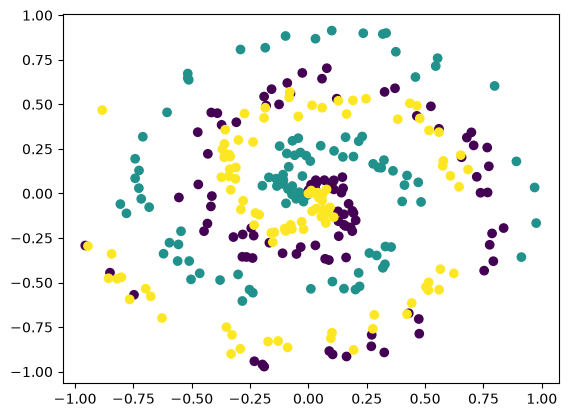

In [44]:
x, y = spiral_data(samples=100, classes=3)
plt.scatter(x[:,0], x[:,1], c=y)

plt.show()

In [45]:
print(x.shape, y.shape) # 2 inputs - 3 outputs

(300, 2) (300,)


In [46]:
# layer 1
l1 = DenseLayer(3, 2) # neurons, inputs
af1 = ActivationFunction()
op1 = af1.ReLU(l1.forward(x))

# ouput layer
l2 = DenseLayer(3, 3)
af2 = ActivationFunction()
op2 = af2.Softmax(l2.forward(op1))

op2.shape

(300, 3)

In [50]:
y_endcoded = np.eye(3)[y]
y_endcoded.shape

(300, 3)

In [53]:
loss = Loss()
ccel = loss.CatergoricalCrossEntropyLoss(y_endcoded, op2)
ccel.shape

(300,)

In [55]:
overall_loss = ccel.mean()
overall_loss

np.float64(1.2329589467937285)

In [56]:
acc = loss.accuracy(y_endcoded, op2)

ValueError: operands could not be broadcast together with shapes (300,) (300,3) 